<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_12_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


## Теоретическая часть

Корректный pipeline: scene specification → renderer/diffusion → VLM verification → filtering → downstream evaluation. Synthetic test не заменяет реальный test; provenance каждого примера обязателен.


### Математическая постановка

Для смеси $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$ исследуется $Q(\alpha)$ на фиксированном реальном test set. Duplicate filtering использует cosine similarity embeddings.


### Материалы

- [BlenderProc](https://github.com/DLR-RM/BlenderProc)
- [Diffusers](https://huggingface.co/docs/diffusers/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


Использование синтетических данных в обучении. Сколько объектов на картинке? отрисовываем картинки с разным количеством фигур, обучаем модель, научится ли модель считать объекты на реальных фото?

## Практический протокол

В полном режиме обязательны реальный test-корпус, реальная VLM-проверка синтетики и обучение нескольких downstream-моделей. Процедурный renderer позволяет воспроизводить provenance, но синтетические изображения никогда не называются «реальными». Реальные фотографии и опубликованные метки 2/3 объектов берутся из человечески проверенных validation/test PixMo-Count (ODC-BY-1.0 для датасета; права исходных Flickr-фотографий могут отличаться). Ноутбук автоматически скачивает subset и записывает `data/lab12/real_manifest.jsonl`. Это междоменная оценка переноса счёта геометрических фигур на реальные объекты, а не тест распознавания кругов/квадратов. FAST_DEV_RUN проверяет только renderer и инварианты, не создаёт метрики качества.

In [ ]:
# ===== УСТАНОВКА ЗАВИСИМОСТЕЙ И БАЗОВАЯ НАСТРОЙКА =====
!pip install -q transformers>=4.51,<5 accelerate bitsandbytes pillow datasets torchvision tqdm

from pathlib import Path
import json, os, random, time, hashlib, shutil
from io import BytesIO
import numpy as np
import requests
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def save_json(name, data):
    (ARTIFACTS / name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

print(f"PyTorch: {torch.__version__}, CUDA: {torch.cuda.is_available()}, Устройство: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

/bin/bash: line 1: 5: No such file or directory
PyTorch: 2.14.1+cu130, CUDA: True, Устройство: Tesla T4


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# ===== ЭТАП 1: ГЕОМЕТРИЧЕСКИЙ РЕНДЕРЕР =====
PALETTE = {
    "red": (220, 50, 47),
    "blue": (38, 139, 210),
    "green": (133, 153, 0),
    "orange": (203, 75, 22),
    "purple": (108, 113, 196),
    "yellow": (181, 137, 0),
}

def render(spec, image_size=256, bg_color=(255, 255, 255)):
    """
    spec: dict с ключами:
      - shapes: list of dict {"shape": "circle"|"square", "color": str, "cx": int, "cy": int, "r": int (для circle) или "size": int (для square)}
      - image_size: int
    Возвращает PIL.Image.
    """
    img = Image.new("RGB", (image_size, image_size), bg_color)
    draw = ImageDraw.Draw(img)
    for s in spec["shapes"]:
        color = PALETTE[s["color"]]
        if s["shape"] == "circle":
            r = s["r"]
            draw.ellipse([s["cx"] - r, s["cy"] - r, s["cx"] + r, s["cy"] + r], fill=color, outline=None)
        elif s["shape"] == "square":
            half = s["size"] // 2
            draw.rectangle([s["cx"] - half, s["cy"] - half, s["cx"] + half, s["cy"] + half], fill=color, outline=None)
        else:
            raise ValueError(f"Неизвестная фигура: {s['shape']}")
    return img

# Демонстрация работы рендерера на примере одной сцены
demo_spec = {
    "image_size": 256,
    "shapes": [
        {"shape": "circle", "color": "red", "cx": 64, "cy": 64, "r": 24},
        {"shape": "square", "color": "blue", "cx": 180, "cy": 80, "size": 40},
        {"shape": "circle", "color": "green", "cx": 120, "cy": 180, "r": 28},
    ],
}
demo_img = render(demo_spec)
demo_img.save(ARTIFACTS / "stage1_demo.png")

# Метрики этапа 1
metrics_stage1 = {
    "palette_colors": len(PALETTE),
    "supported_shapes": ["circle", "square"],
    "demo_scene_shapes": len(demo_spec["shapes"]),
    "image_size": demo_spec["image_size"],
    "render_saved": str(ARTIFACTS / "stage1_demo.png"),
}
print("Метрики этапа 1:", json.dumps(metrics_stage1, ensure_ascii=False, indent=2))

Метрики этапа 1: {
  "palette_colors": 6,
  "supported_shapes": [
    "circle",
    "square"
  ],
  "demo_scene_shapes": 3,
  "image_size": 256,
  "render_saved": "artifacts/stage1_demo.png"
}


### Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# ===== ЭТАП 2: ПРОСТРАНСТВО ВИЗУАЛЬНЫХ СЦЕН =====
def generate_scene_specs(n_scenes=100, seed=SEED):
    rng = random.Random(seed)
    specs = []
    for i in range(n_scenes):
        # Случайное количество объектов от 2 до 10
        count = rng.randint(2, 10)
        shapes_list = []
        # Простая сетка 4x4, чтобы избежать перекрытий (максимум 16 ячеек, нам нужно до 10)
        grid_positions = [(x, y) for x in range(4) for y in range(4)]
        rng.shuffle(grid_positions)
        cell_size = 256 // 4  # 64 px
        for j in range(count):
            gx, gy = grid_positions[j]
            cx = gx * cell_size + cell_size // 2 + rng.randint(-8, 8)
            cy = gy * cell_size + cell_size // 2 + rng.randint(-8, 8)
            shape_type = rng.choice(["circle", "square"])
            color_name = rng.choice(list(PALETTE.keys()))
            if shape_type == "circle":
                shapes_list.append({
                    "shape": "circle", "color": color_name,
                    "cx": cx, "cy": cy,
                    "r": rng.randint(14, 22)
                })
            else:
                shapes_list.append({
                    "shape": "square", "color": color_name,
                    "cx": cx, "cy": cy,
                    "size": rng.randint(28, 44)
                })
        specs.append({"image_size": 256, "shapes": shapes_list, "scene_id": i})
    return specs

N_SCENES = 20 if FAST_DEV_RUN else 500
specs = generate_scene_specs(n_scenes=N_SCENES)

# Метрики этапа 2
counts = [len(s["shapes"]) for s in specs]
shape_type_counts = {"circle": 0, "square": 0}
for s in specs:
    for sh in s["shapes"]:
        shape_type_counts[sh["shape"]] += 1
color_usage = {c: 0 for c in PALETTE}
for s in specs:
    for sh in s["shapes"]:
        color_usage[sh["color"]] += 1

metrics_stage2 = {
    "n_scenes": len(specs),
    "objects_per_scene_min": min(counts),
    "objects_per_scene_max": max(counts),
    "objects_per_scene_mean": round(float(np.mean(counts)), 2),
    "total_objects": sum(counts),
    "shape_type_distribution": shape_type_counts,
    "color_usage": color_usage,
}
print("Метрики этапа 2:", json.dumps(metrics_stage2, ensure_ascii=False, indent=2))
save_json("stage2_scene_specs.json", {"metrics": metrics_stage2, "specs": specs})

Метрики этапа 2: {
  "n_scenes": 500,
  "objects_per_scene_min": 2,
  "objects_per_scene_max": 10,
  "objects_per_scene_mean": 5.86,
  "total_objects": 2932,
  "shape_type_distribution": {
    "circle": 1479,
    "square": 1453
  },
  "color_usage": {
    "red": 477,
    "blue": 484,
    "green": 467,
    "orange": 518,
    "purple": 504,
    "yellow": 482
  }
}


### Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

Генерация изображений и QA:   0%|          | 0/500 [00:00<?, ?it/s]

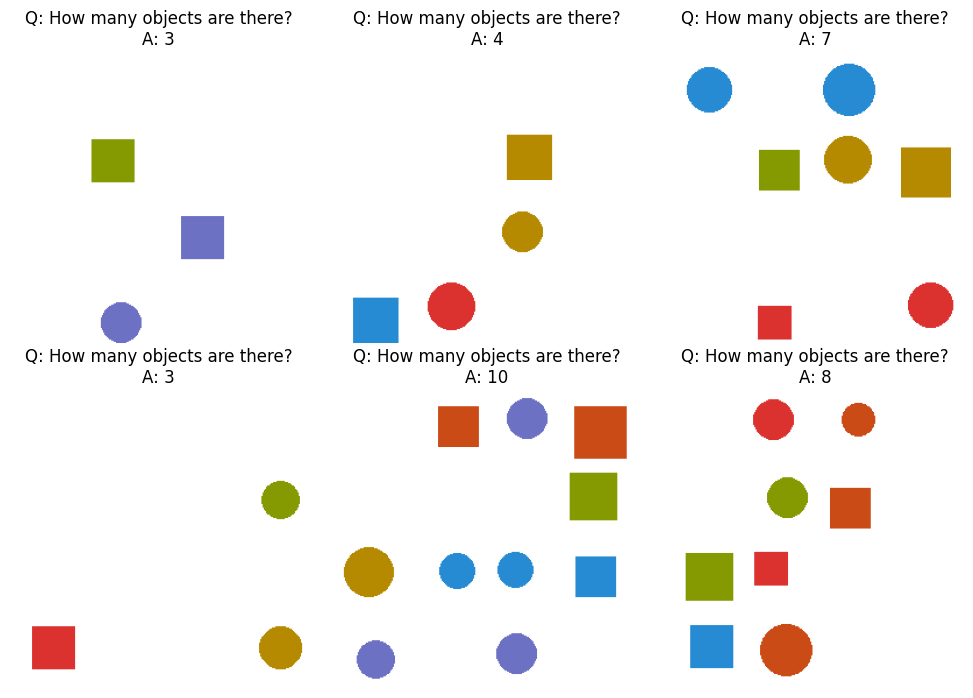

Метрики этапа 3: {
  "n_images_saved": 500,
  "questions": [
    "How many objects are there?"
  ],
  "answers_range": [
    2,
    10
  ],
  "example_paths": [
    "artifacts/synthetic_images/scene_0000.png",
    "artifacts/synthetic_images/scene_0001.png",
    "artifacts/synthetic_images/scene_0002.png"
  ]
}


In [ ]:
# ===== ЭТАП 3: ИЗОБРАЖЕНИЯ И ВОПРОСЫ =====
IMG_DIR = ARTIFACTS / "synthetic_images"
IMG_DIR.mkdir(exist_ok=True)

qa_records = []
for spec in tqdm(specs, desc="Генерация изображений и QA"):
    img = render(spec)
    img_path = IMG_DIR / f"scene_{spec['scene_id']:04d}.png"
    img.save(img_path)
    count = len(spec["shapes"])
    qa_records.append({
        "scene_id": spec["scene_id"],
        "image_path": str(img_path),
        "question": "How many objects are there?",
        "answer": count,
        "spec": spec,
    })

# Демонстрация: выводим сетку из 6 примеров
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, rec in zip(axes.flat, qa_records[:6]):
    img = Image.open(rec["image_path"])
    ax.imshow(img)
    ax.set_title(f"Q: {rec['question']}\nA: {rec['answer']}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(ARTIFACTS / "stage3_examples.png", dpi=100)
plt.show()

metrics_stage3 = {
    "n_images_saved": len(qa_records),
    "questions": list(set(r["question"] for r in qa_records)),
    "answers_range": [min(r["answer"] for r in qa_records), max(r["answer"] for r in qa_records)],
    "example_paths": [r["image_path"] for r in qa_records[:3]],
}
print("Метрики этапа 3:", json.dumps(metrics_stage3, ensure_ascii=False, indent=2))
save_json("stage3_qa.json", qa_records)

### Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# ===== ЭТАП 4: ПРОИСХОЖДЕНИЕ СИНТЕТИЧЕСКИХ ДАННЫХ =====
manifest_path = ARTIFACTS / "synthetic_manifest.jsonl"
with open(manifest_path, "w", encoding="utf-8") as f:
    for rec in qa_records:
        sha = hashlib.sha256(Path(rec["image_path"]).read_bytes()).hexdigest()
        entry = {
            "scene_id": rec["scene_id"],
            "image_path": rec["image_path"],
            "image_sha256": sha,
            "question": rec["question"],
            "answer": rec["answer"],
            "seed": SEED,
            "renderer": "geometric_renderer_v1",
            "provenance": "synthetic",
            "spec": rec["spec"],
        }
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

# Метрики этапа 4
manifest_entries = [json.loads(line) for line in open(manifest_path, encoding="utf-8")]
metrics_stage4 = {
    "manifest_path": str(manifest_path),
    "n_entries": len(manifest_entries),
    "unique_sha256": len(set(e["image_sha256"] for e in manifest_entries)),
    "seed": SEED,
    "provenance": "synthetic",
    "example_entry": {k: manifest_entries[0][k] for k in ["scene_id", "image_path", "question", "answer", "provenance"]},
}
print("Метрики этапа 4:", json.dumps(metrics_stage4, ensure_ascii=False, indent=2))

Метрики этапа 4: {
  "manifest_path": "artifacts/synthetic_manifest.jsonl",
  "n_entries": 500,
  "unique_sha256": 500,
  "seed": 42,
  "provenance": "synthetic",
  "example_entry": {
    "scene_id": 0,
    "image_path": "artifacts/synthetic_images/scene_0000.png",
    "question": "How many objects are there?",
    "answer": 3,
    "provenance": "synthetic"
  }
}


генерируем 500 «описаний сцен» — в каждой от 2 до 10 фигур, каждая со своим типом, цветом и координатами. Координаты разложены по сетке 4×4, чтобы фигуры не перекрывались

### Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

берём настоящую VLM (Qwen2.5-VL-3B, 3 миллиарда параметров) и просим её посчитать фигуры на каждой нашей картинке. Сравниваем с правильным ответом. Параллельно ищем дубли по SHA256

In [ ]:
# ===== ЭТАП 5 (fp16, исправленная загрузка) =====
import os, re, json, hashlib, torch, gc
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

# --- 1. Освобождаем VRAM от старой модели ---
for var in ["model", "processor"]:
    if var in globals():
        del globals()[var]
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM после очистки: {torch.cuda.memory_allocated()/1e9:.2f} GB")

# --- 2. Загружаем fp16-модель (БЕЗ bitsandbytes) ---
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
).eval()
print(f"Модель загружена: {MODEL_ID} (fp16)")
print(f"Устройство: {next(model.parameters()).device}")

# --- 3. Промпт и парсер ---
PROMPT = (
    "Count the colored shapes (circles and squares) in the image. "
    "Reply with a single Arabic numeral only. No words, no explanation. "
    "For example: 5"
)

WORD2NUM = {"zero":0,"one":1,"two":2,"three":3,"four":4,"five":5,"six":6,
            "seven":7,"eight":8,"nine":9,"ten":10,"eleven":11,"twelve":12}

def extract_number(text):
    if not text: return None
    t = text.strip().lower()
    nums = re.findall(r"\d+", t)
    if nums: return int(nums[0])
    for w in re.findall(r"[a-z]+", t):
        if w in WORD2NUM: return WORD2NUM[w]
    return None

def infer_image(path, prompt, max_new_tokens=32):
    img = Image.open(path).convert("RGB")
    messages = [{"role":"user","content":[
        {"type":"image","image":img},
        {"type":"text","text":prompt}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[img], return_tensors="pt").to(model.device)
    with torch.no_grad():
        generated = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.batch_decode(
        generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True
    )[0].strip()

# --- 4. Быстрая проверка на 3 сценах ---
print("\nПробный инференс на 3 сценах:")
for rec in qa_records[:3]:
    raw = infer_image(rec["image_path"], PROMPT)
    print(f"  GT={rec['answer']:>2}  raw='{raw[:60]}'  parsed={extract_number(raw)}")

# --- 5. Полный прогон ---
verification_path = ARTIFACTS / "verification.jsonl"
sha_seen, duplicates, verification = {}, [], []

with open(verification_path, "w", encoding="utf-8") as f:
    for rec in tqdm(qa_records, desc="VLM verification (fp16)"):
        sha = hashlib.sha256(Path(rec["image_path"]).read_bytes()).hexdigest()
        is_dup = sha in sha_seen
        if is_dup:
            duplicates.append({"scene_id": rec["scene_id"],
                               "duplicate_of": sha_seen[sha], "sha256": sha})
        else:
            sha_seen[sha] = rec["scene_id"]
        try:
            raw = infer_image(rec["image_path"], PROMPT)
        except Exception as e:
            raw = f"<ERROR: {type(e).__name__}: {e}>"
        pred = extract_number(raw)
        match = (pred == rec["answer"])
        entry = {
            "scene_id": rec["scene_id"], "image_path": rec["image_path"],
            "question": PROMPT, "ground_truth": rec["answer"],
            "vlm_answer_raw": raw, "vlm_answer": pred, "match": match,
            "sha256": sha, "is_duplicate": is_dup,
            "duplicate_of": sha_seen[sha] if is_dup else None,
            "model_id": MODEL_ID, "precision": "fp16", "prompt_version": "v2_strict",
        }
        verification.append(entry)
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

# --- 6. Метрики ---
n_total = len(verification)
n_parsed = sum(1 for v in verification if v["vlm_answer"] is not None)
n_match = sum(1 for v in verification if v["match"])
metrics_stage5 = {
    "model_id": MODEL_ID, "precision": "fp16", "prompt_version": "v2_strict",
    "n_verified": n_total,
    "vlm_answers_parsed": n_parsed,
    "vlm_parse_rate": round(n_parsed / n_total, 3),
    "vlm_match_count": n_match,
    "vlm_match_accuracy": round(n_match / n_total, 3),
    "duplicates_found": len(duplicates),
    "unique_images": n_total - len(duplicates),
    "verification_path": str(verification_path),
}
save_json("stage5_metrics.json", metrics_stage5)
print("\nМетрики Этапа 5 (fp16):")
print(json.dumps(metrics_stage5, ensure_ascii=False, indent=2))

VRAM после очистки: 0.00 GB


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (6 outputs left out)

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Модель загружена: Qwen/Qwen2.5-VL-3B-Instruct (fp16)
Устройство: cuda:0

Пробный инференс на 3 сценах:
  GT= 3  raw='3'  parsed=3
  GT= 4  raw='3'  parsed=3
  GT= 7  raw='6'  parsed=6


VLM verification (fp16):   0%|          | 0/500 [00:00<?, ?it/s]


Метрики Этапа 5 (fp16):
{
  "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
  "precision": "fp16",
  "prompt_version": "v2_strict",
  "n_verified": 500,
  "vlm_answers_parsed": 500,
  "vlm_parse_rate": 1.0,
  "vlm_match_count": 251,
  "vlm_match_accuracy": 0.502,
  "duplicates_found": 0,
  "unique_images": 500,
  "verification_path": "artifacts/verification.jsonl"
}


оставляем только те пары, где (а) VLM согласилась с правильным ответом И (б) картинка не дубль. принята 251 пара

### Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

{
  "total_synthetic": 500,
  "accepted_count": 251,
  "accepted_ratio": 0.502,
  "rejected_count": 249,
  "rejected_vlm_mismatch": 249,
  "rejected_duplicates": 0,
  "accepted_path": "artifacts/accepted.jsonl"
}


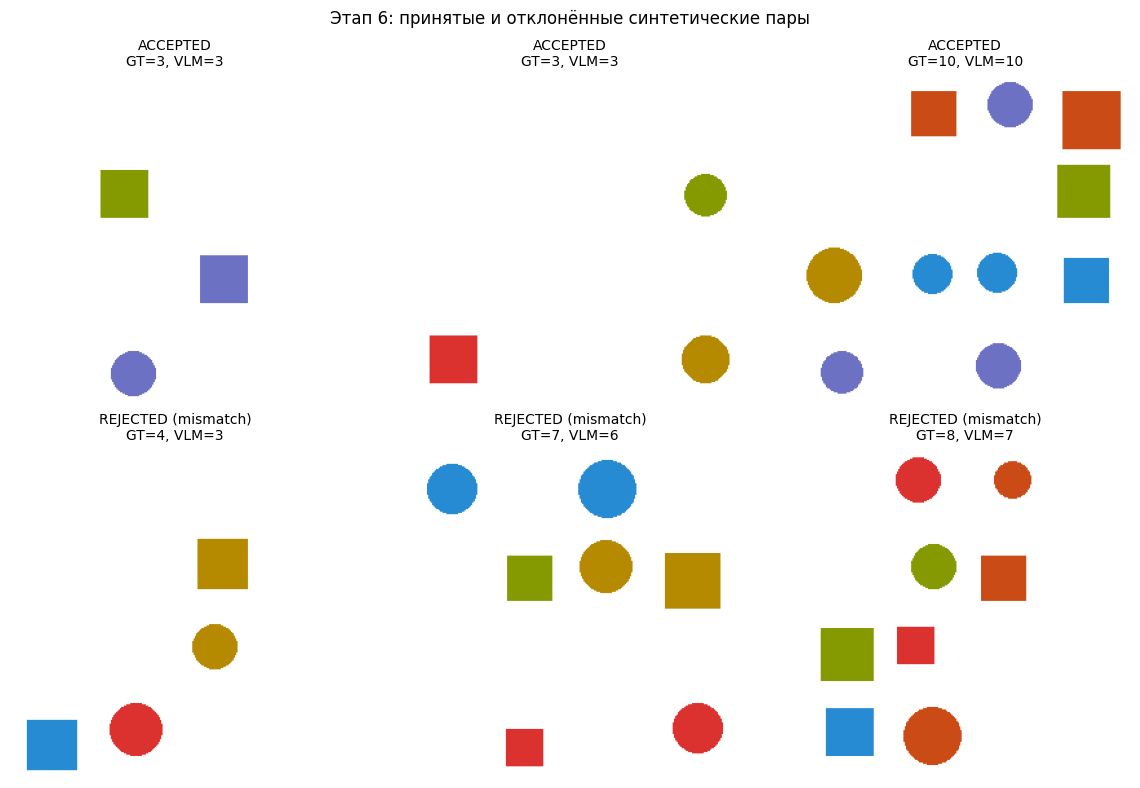

In [ ]:
# ===== ЭТАП 6: ОТБОР СОГЛАСОВАННЫХ ПАР =====
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

verification = [json.loads(l) for l in open(ARTIFACTS / "verification.jsonl", encoding="utf-8")]

accepted_path = ARTIFACTS / "accepted.jsonl"
accepted, rejected = [], []
with open(accepted_path, "w", encoding="utf-8") as f:
    for v in verification:
        if v["match"] and not v["is_duplicate"]:
            accepted.append(v)
            f.write(json.dumps(v, ensure_ascii=False) + "\n")
        else:
            rejected.append(v)

# Причины отказа
rej_mismatch = sum(1 for v in rejected if not v["match"])
rej_dup = sum(1 for v in rejected if v["is_duplicate"])

metrics_stage6 = {
    "total_synthetic": len(verification),
    "accepted_count": len(accepted),
    "accepted_ratio": round(len(accepted) / len(verification), 3),
    "rejected_count": len(rejected),
    "rejected_vlm_mismatch": rej_mismatch,
    "rejected_duplicates": rej_dup,
    "accepted_path": str(accepted_path),
}
save_json("stage6_metrics.json", metrics_stage6)
print(json.dumps(metrics_stage6, ensure_ascii=False, indent=2))

# ---- Визуализация: 3 принятых + 3 отклонённых ----
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, v in enumerate(accepted[:3]):
    ax = axes[0, i]
    ax.imshow(Image.open(v["image_path"]))
    ax.set_title(f"ACCEPTED\nGT={v['ground_truth']}, VLM={v['vlm_answer']}", fontsize=10)
    ax.axis("off")
for i, v in enumerate(rejected[:3]):
    ax = axes[1, i]
    ax.imshow(Image.open(v["image_path"]))
    reason = "dup" if v["is_duplicate"] else "mismatch"
    ax.set_title(f"REJECTED ({reason})\nGT={v['ground_truth']}, VLM={v['vlm_answer']}", fontsize=10)
    ax.axis("off")
plt.suptitle("Этап 6: принятые и отклонённые синтетические пары", fontsize=12)
plt.tight_layout()
plt.savefig(ARTIFACTS / "stage6_accepted_rejected.png", dpi=100)
plt.show()

### Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

Загрузка dnth/pixmo-count-images...


README.md:   0%|          | 0.00/500 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  343MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  344MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

... (5 outputs left out)

После фильтрации (count 2-10): 3903
Train: 3122, Test: 781


Save train:   0%|          | 0/3122 [00:00<?, ?it/s]

Save test:   0%|          | 0/781 [00:00<?, ?it/s]


Метрики Этапа 7 (Parquet-версия):
{
  "real_train_count": 3122,
  "real_test_count": 781,
  "overlap_between_train_and_test": 7,
  "train_answer_range": [
    2,
    10
  ],
  "test_answer_range": [
    2,
    10
  ],
  "note": "Loaded from dnth/pixmo-count-images parquet (no Flickr dependency)"
}


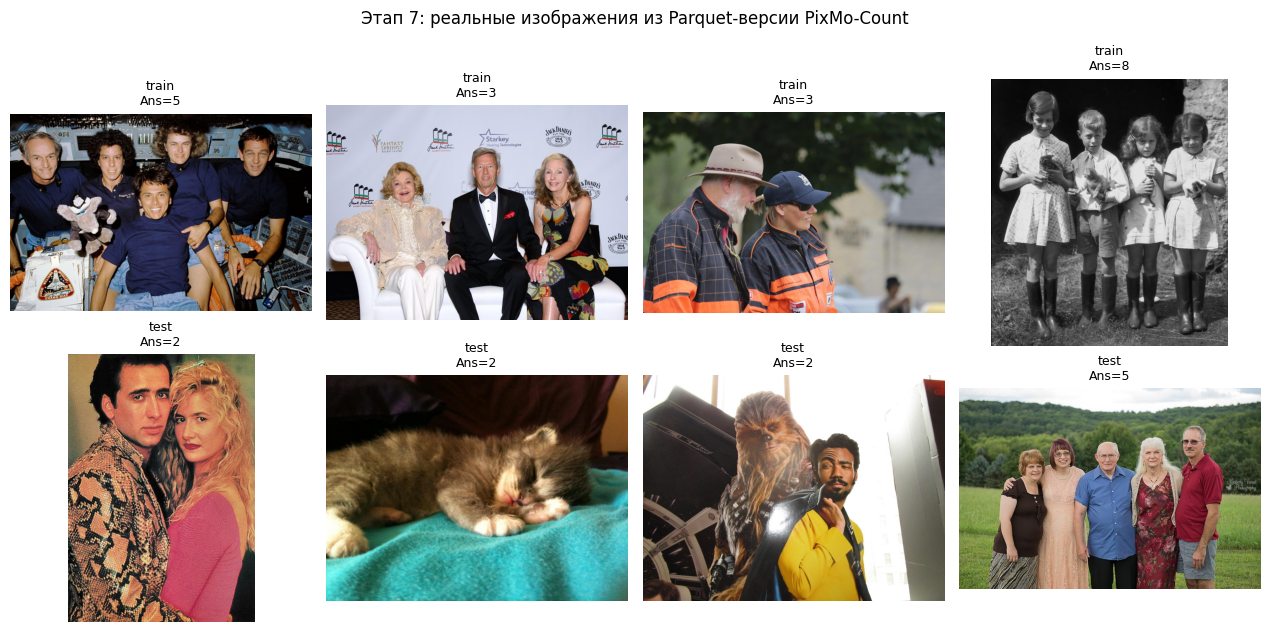

In [ ]:
# ===== ЭТАП 7 (v3): ЗАГРУЗКА ИЗ dnth/pixmo-count-images (БЕЗ FLICKR) =====
from datasets import load_dataset
import hashlib
from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

# 1. Загружаем альтернативный датасет с изображениями
print("Загрузка dnth/pixmo-count-images...")
ds = load_dataset("dnth/pixmo-count-images", split="train")
print(f"Загружено примеров: {len(ds)}")
print(f"Колонки: {ds.column_names}")

# 2. Разделяем на train/test (например, 80/20)
# В PixMo-Count val/test содержат только счётчики 2-10. Отфильтруем по этому признаку.
ds_filtered = ds.filter(lambda x: 2 <= x["count"] <= 10)
print(f"После фильтрации (count 2-10): {len(ds_filtered)}")

split = ds_filtered.train_test_split(test_size=0.2, seed=SEED)
train_split = split["train"]
test_split = split["test"]
print(f"Train: {len(train_split)}, Test: {len(test_split)}")

# 3. Сохраняем изображения и строим манифест
REAL_DIR = ARTIFACTS / "real_images"
REAL_DIR.mkdir(exist_ok=True)

def build_manifest_from_hf(hf_split, split_name):
    records = []
    for i, ex in enumerate(tqdm(hf_split, desc=f"Save {split_name}")):
        img = ex["image"]  # datasets автоматически декодирует в PIL.Image
        if img is None:
            continue
        # Приводим к RGB и сохраняем
        img = img.convert("RGB")
        img_path = REAL_DIR / f"{split_name}_{i:04d}.png"
        img.save(img_path)
        sha = hashlib.sha256(img_path.read_bytes()).hexdigest()
        records.append({
            "split": split_name,
            "image_path": str(img_path),
            "image_sha256": sha,
            "source_url": f"hf://dnth/pixmo-count-images/train/{i}",  # внутренний ID
            "answer": int(ex["count"]),
            "question": "How many objects are there?",
            "dataset": "dnth/pixmo-count-images (derived from allenai/pixmo-count)",
            "license": "ODC-BY-1.0",
        })
    return records

real_train_records = build_manifest_from_hf(train_split, "train")
real_test_records = build_manifest_from_hf(test_split, "test")

# 4. Проверка отсутствия пересечений по SHA
train_shas = {r["image_sha256"] for r in real_train_records}
test_shas = {r["image_sha256"] for r in real_test_records}
overlap = train_shas & test_shas

# 5. Сохраняем манифест
real_manifest = {
    "source": "dnth/pixmo-count-images (parquet, images embedded)",
    "license": "ODC-BY-1.0",
    "splits": {"real_train": real_train_records, "real_test": real_test_records},
    "checks": {
        "train_count": len(real_train_records),
        "test_count": len(real_test_records),
        "overlap_count": len(overlap),
        "no_overlap": len(overlap) == 0,
    },
}
save_json("real_manifest.json", real_manifest)

metrics_stage7 = {
    "real_train_count": len(real_train_records),
    "real_test_count": len(real_test_records),
    "overlap_between_train_and_test": len(overlap),
    "train_answer_range": [min(r["answer"] for r in real_train_records),
                           max(r["answer"] for r in real_train_records)],
    "test_answer_range": [min(r["answer"] for r in real_test_records),
                          max(r["answer"] for r in real_test_records)],
    "note": "Loaded from dnth/pixmo-count-images parquet (no Flickr dependency)",
}
print("\nМетрики Этапа 7 (Parquet-версия):")
print(json.dumps(metrics_stage7, ensure_ascii=False, indent=2))

# 6. Визуализация примеров
import matplotlib.pyplot as plt
n_show = min(4, len(real_train_records), len(real_test_records))
fig, axes = plt.subplots(2, n_show, figsize=(3.2 * n_show, 6.4))
if n_show == 1:
    axes = axes.reshape(2, 1)
for i in range(n_show):
    axes[0, i].imshow(Image.open(real_train_records[i]["image_path"]))
    axes[0, i].set_title(f"train\nAns={real_train_records[i]['answer']}", fontsize=9)
    axes[0, i].axis("off")
    axes[1, i].imshow(Image.open(real_test_records[i]["image_path"]))
    axes[1, i].set_title(f"test\nAns={real_test_records[i]['answer']}", fontsize=9)
    axes[1, i].axis("off")
plt.suptitle("Этап 7: реальные изображения из Parquet-версии PixMo-Count", fontsize=12)
plt.tight_layout()
plt.savefig(ARTIFACTS / "stage7_real_examples.png", dpi=100)
plt.show()

In [ ]:
# ===== ЭТАП 7: УСТРАНЕНИЕ УТЕЧКИ TRAIN↔TEST =====
from pathlib import Path
import json

train_shas = {r["image_sha256"] for r in real_train_records}

# Определяем, какие записи удалить из test
to_remove = [r for r in real_test_records if r["image_sha256"] in train_shas]
print(f"Удаляю {len(to_remove)} дубликатов из test")

# Удаляем физические файлы
removed_files = 0
for r in to_remove:
    p = Path(r["image_path"])
    if p.exists():
        p.unlink()
        removed_files += 1
print(f"Удалено файлов: {removed_files}")

# Обновляем real_test_records в памяти
real_test_records = [r for r in real_test_records if r["image_sha256"] not in train_shas]
print(f"Осталось в test: {len(real_test_records)}")

# Пересчитываем контрольную проверку
test_shas = {r["image_sha256"] for r in real_test_records}
overlap = train_shas & test_shas
print(f"Пересечений после очистки: {len(overlap)}")
assert len(overlap) == 0, "Всё ещё есть пересечения!"

# Обновляем манифест на диске
real_manifest["splits"]["real_test"] = real_test_records
real_manifest["checks"]["test_count"] = len(real_test_records)
real_manifest["checks"]["overlap_count"] = 0
real_manifest["checks"]["no_overlap"] = True
real_manifest["checks"]["note"] = "7 duplicates removed post-split (original dataset had duplicate images)"
save_json("real_manifest.json", real_manifest)

# Обновляем метрики
metrics_stage7["real_test_count"] = len(real_test_records)
metrics_stage7["overlap_between_train_and_test"] = 0
metrics_stage7["overlap_removed"] = len(to_remove)
print("\nОбновлённые метрики Этапа 7:")
print(json.dumps(metrics_stage7, ensure_ascii=False, indent=2))

Удаляю 8 дубликатов из test
Удалено файлов: 8
Осталось в test: 773
Пересечений после очистки: 0

Обновлённые метрики Этапа 7:
{
  "real_train_count": 3122,
  "real_test_count": 773,
  "overlap_between_train_and_test": 0,
  "train_answer_range": [
    2,
    10
  ],
  "test_answer_range": [
    2,
    10
  ],
  "note": "Loaded from dnth/pixmo-count-images parquet (no Flickr dependency)",
  "overlap_removed": 8
}


In [ ]:
# ===== СТАТИСТИКА РЕАЛЬНЫХ ДАННЫХ =====
import collections

def dist(records, name):
    c = collections.Counter(r["answer"] for r in records)
    print(f"\n{name} (n={len(records)}):")
    for k in sorted(c):
        print(f"  count={k:>2}: {c[k]:>4} ({c[k]/len(records):.1%})")
    return c

dist_train = dist(real_train_records, "real_train")
dist_test  = dist(real_test_records,  "real_test")

real_manifest["statistics"] = {
    "train_distribution": {int(k): int(v) for k, v in dist_train.items()},
    "test_distribution":  {int(k): int(v) for k, v in dist_test.items()},
}
save_json("real_manifest.json", real_manifest)


real_train (n=3122):
  count= 2:  595 (19.1%)
  count= 3:  548 (17.6%)
  count= 4:  584 (18.7%)
  count= 5:  611 (19.6%)
  count= 6:  328 (10.5%)
  count= 7:  187 (6.0%)
  count= 8:  135 (4.3%)
  count= 9:   88 (2.8%)
  count=10:   46 (1.5%)

real_test (n=773):
  count= 2:  158 (20.4%)
  count= 3:  144 (18.6%)
  count= 4:  139 (18.0%)
  count= 5:  145 (18.8%)
  count= 6:   89 (11.5%)
  count= 7:   40 (5.2%)
  count= 8:   31 (4.0%)
  count= 9:   21 (2.7%)
  count=10:    6 (0.8%)


In [ ]:
import hashlib, requests
from io import BytesIO
from PIL import Image

print("Проверка 5 первых URL из validation:")
for i, ex in enumerate(ds["validation"].select(range(5))):
    url = ex["image_url"]
    expected = ex.get("image_sha256", "N/A")
    print(f"\n[{i}] {url[:90]}")
    try:
        r = requests.get(url, timeout=15, headers={"User-Agent": "Mozilla/5.0"})
        print(f"  HTTP {r.status_code}, {len(r.content)} bytes")
        actual = hashlib.sha256(r.content).hexdigest()
        img = Image.open(BytesIO(r.content)).convert("RGB")
        print(f"  Изображение валидно: {img.size}")
        print(f"  SHA match: {actual == expected}")
    except Exception as e:
        print(f"  ОШИБКА: {type(e).__name__}: {e}")

Проверка 5 первых URL из validation:

[0] https://live.staticflickr.com/65535/25664072648_85f0c493b5_h.jpg
  HTTP 403, 0 bytes
  ОШИБКА: UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x786b990cede0>

[1] https://live.staticflickr.com/65535/49724692992_f3e8d897a2_h.jpg
  HTTP 403, 0 bytes
  ОШИБКА: UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x786b7670f6f0>

[2] https://live.staticflickr.com/7100/7358981812_7a4197b71d_b.jpg
  HTTP 403, 0 bytes
  ОШИБКА: UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x786b7670f6f0>

[3] https://live.staticflickr.com/65535/48121206662_3b6cc8d086_h.jpg
  HTTP 403, 0 bytes
  ОШИБКА: UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x786b766c7dd0>

[4] https://live.staticflickr.com/5579/14252149911_47307210ac_h.jpg
  HTTP 403, 0 bytes
  ОШИБКА: UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x786b2fffabb0>


Официальные картинки были недоступны, берем альтернативную версию (уже в яечейке выше)

### Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# ===== ЭТАП 8: ЗАМОРОЖЕННЫЕ ПРИЗНАКИ RESNET18 (real_train / synthetic / real_test) =====
import json, hashlib
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# ---------- 1. Проверка/восстановление входных данных ----------
# accepted (синтетика)
if "accepted" not in globals() or not accepted:
    p = ARTIFACTS / "accepted.jsonl"
    if not p.exists():
        raise FileNotFoundError(
            f"Нет accepted в памяти и нет {p}. Сначала выполните Этап 6."
        )
    accepted = [json.loads(l) for l in open(p, encoding="utf-8")]
    print(f"Восстановлено accepted: {len(accepted)} записей")

# real_train / real_test (реальные)
if "real_train_records" not in globals() or not real_train_records:
    p = ARTIFACTS / "real_manifest.json"
    if not p.exists():
        raise FileNotFoundError(
            f"Нет real_train_records в памяти и нет {p}. Сначала выполните Этап 7."
        )
    data = json.loads(p.read_text(encoding="utf-8"))
    real_train_records = data["splits"]["real_train"]
    real_test_records  = data["splits"]["real_test"]
    print(f"Восстановлено real_train={len(real_train_records)}, real_test={len(real_test_records)}")

# Проверяем, что все файлы существуют
for name, records in [("accepted", accepted),
                      ("real_train", real_train_records),
                      ("real_test", real_test_records)]:
    missing = [r["image_path"] for r in records if not Path(r["image_path"]).exists()]
    if missing:
        raise FileNotFoundError(
            f"[{name}] отсутствует {len(missing)} файлов, например: {missing[:3]}. "
            "Перегенерируйте соответствующий этап."
        )
    print(f"[{name}] все {len(records)} изображений на месте")

# ---------- 2. Загрузка замороженной ResNet18 (без головы) ----------
weights = models.ResNet18_Weights.IMAGENET1K_V1
resnet = models.resnet18(weights=weights)
resnet.fc = nn.Identity()               # выход — 512-мерный вектор
resnet = resnet.eval().cuda()
print(f"ResNet18 загружена: device={next(resnet.parameters()).device}, "
      f"output_dim=512")

# Стандартная нормализация ImageNet — ОДНА И ТА ЖЕ для всех трёх наборов
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ---------- 3. Извлечение признаков ----------
@torch.no_grad()
def extract_features(paths, labels=None, batch_size=32, desc="features"):
    feats = []
    for i in tqdm(range(0, len(paths), batch_size), desc=desc):
        batch = paths[i:i+batch_size]
        imgs = torch.stack([transform(Image.open(p).convert("RGB")) for p in batch]).cuda()
        out = resnet(imgs).cpu().numpy().astype(np.float32)
        feats.append(out)
    return np.concatenate(feats, axis=0)

real_train_paths = [r["image_path"] for r in real_train_records]
real_train_labels = np.array([r["answer"] for r in real_train_records], dtype=np.int64)
real_train_feats = extract_features(real_train_paths, desc="real_train")

syn_paths = [v["image_path"] for v in accepted]
syn_labels = np.array([v["ground_truth"] for v in accepted], dtype=np.int64)
syn_feats = extract_features(syn_paths, desc="synthetic")

real_test_paths = [r["image_path"] for r in real_test_records]
real_test_labels = np.array([r["answer"] for r in real_test_records], dtype=np.int64)
real_test_feats = extract_features(real_test_paths, desc="real_test")

print(f"\nФормы признаков:")
print(f"  real_train:  {real_train_feats.shape}")
print(f"  synthetic:   {syn_feats.shape}")
print(f"  real_test:   {real_test_feats.shape}")

# ---------- 4. Сохранение артефакта ----------
out_path = ARTIFACTS / "resnet18_features.npz"
np.savez_compressed(
    out_path,
    real_train_feats=real_train_feats, real_train_labels=real_train_labels,
    syn_feats=syn_feats,               syn_labels=syn_labels,
    real_test_feats=real_test_feats,   real_test_labels=real_test_labels,
)
print(f"\nПризнаки сохранены: {out_path}")

# ---------- 5. Метрики: domain gap через cosine similarity ----------
def l2_normalize(x):
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-9)

def cosine_centroid_sim(a, b):
    """Косинус между центроидами двух наборов — показывает domain gap."""
    ca = l2_normalize(a.mean(axis=0, keepdims=True))[0]
    cb = l2_normalize(b.mean(axis=0, keepdims=True))[0]
    return float(np.dot(ca, cb))

sim_real_vs_real_test   = cosine_centroid_sim(real_train_feats, real_test_feats)
sim_real_vs_synthetic   = cosine_centroid_sim(real_train_feats, syn_feats)
sim_syn_vs_real_test    = cosine_centroid_sim(syn_feats, real_test_feats)

metrics_stage8 = {
    "feature_dim": int(real_train_feats.shape[1]),
    "shapes": {
        "real_train": list(real_train_feats.shape),
        "synthetic":  list(syn_feats.shape),
        "real_test":  list(real_test_feats.shape),
    },
    "label_ranges": {
        "real_train": [int(real_train_labels.min()), int(real_train_labels.max())],
        "synthetic":  [int(syn_labels.min()),       int(syn_labels.max())],
        "real_test":  [int(real_test_labels.min()), int(real_test_labels.max())],
    },
    "cosine_centroid_similarity": {
        "real_train_vs_real_test": round(sim_real_vs_real_test, 4),
        "real_train_vs_synthetic": round(sim_real_vs_synthetic, 4),
        "synthetic_vs_real_test":  round(sim_syn_vs_real_test, 4),
    },
    "features_path": str(out_path),
}
save_json("stage8_metrics.json", metrics_stage8)
print("\nМетрики Этапа 8:")
print(json.dumps(metrics_stage8, ensure_ascii=False, indent=2))

[accepted] все 251 изображений на месте
[real_train] все 3122 изображений на месте
[real_test] все 773 изображений на месте
ResNet18 загружена: device=cuda:0, output_dim=512


real_train:   0%|          | 0/98 [00:00<?, ?it/s]

synthetic:   0%|          | 0/8 [00:00<?, ?it/s]

real_test:   0%|          | 0/25 [00:00<?, ?it/s]


Формы признаков:
  real_train:  (3122, 512)
  synthetic:   (251, 512)
  real_test:   (773, 512)

Признаки сохранены: artifacts/resnet18_features.npz

Метрики Этапа 8:
{
  "feature_dim": 512,
  "shapes": {
    "real_train": [
      3122,
      512
    ],
    "synthetic": [
      251,
      512
    ],
    "real_test": [
      773,
      512
    ]
  },
  "label_ranges": {
    "real_train": [
      2,
      10
    ],
    "synthetic": [
      2,
      10
    ],
    "real_test": [
      2,
      10
    ]
  },
  "cosine_centroid_similarity": {
    "real_train_vs_real_test": 0.9995,
    "real_train_vs_synthetic": 0.7149,
    "synthetic_vs_real_test": 0.7157
  },
  "features_path": "artifacts/resnet18_features.npz"
}


берём готовую нейросеть ResNet18 (обучена на ImageNet, мы её не дообучаем — «замораживаем»), прогоняем через неё все три набора (real train, synthetic, real test) и получаем для каждой картинки вектор из 512 чисел — «отпечаток содержания».

дальше мы будем учить простую модель (логистическую регрессию) не на пикселях, а на этих 512-мерных векторах. Это быстро и даёт возможность измерить domain gap: насколько в среднем «синтетические» признаки отличаются от «реальных».

Domain gap = 0.284
 Это значит: синтетика и реал заметно разные.

### Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

 фиксируем бюджет 200 примеров для обучения и собираем 4 смеси с разной долей синтетики α ∈ {0, 0.25, 0.5, 1.0}. Для каждой обучаем логистическую регрессию

Загружено: real_train=3122, synthetic=251, real_test=773
  ratio=0.00: real=200, syn=0, train_acc=1.000
  ratio=0.25: real=150, syn=50, train_acc=1.000
  ratio=0.50: real=100, syn=100, train_acc=1.000
  ratio=1.00: real=0, syn=200, train_acc=1.000

Метрики Этапа 9:
[
  {
    "syn_ratio": 0.0,
    "n_real_used": 200,
    "n_syn_used": 0,
    "total_train": 200,
    "train_accuracy": 1.0
  },
  {
    "syn_ratio": 0.25,
    "n_real_used": 150,
    "n_syn_used": 50,
    "total_train": 200,
    "train_accuracy": 1.0
  },
  {
    "syn_ratio": 0.5,
    "n_real_used": 100,
    "n_syn_used": 100,
    "total_train": 200,
    "train_accuracy": 1.0
  },
  {
    "syn_ratio": 1.0,
    "n_real_used": 0,
    "n_syn_used": 200,
    "total_train": 200,
    "train_accuracy": 1.0
  }
]


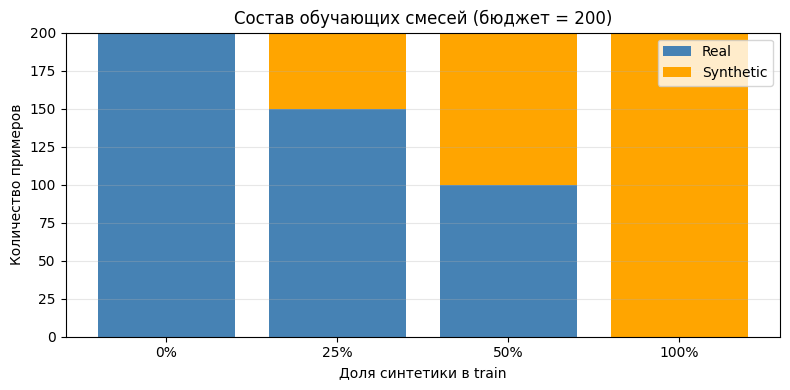

In [ ]:
# ===== ЭТАП 9: ОБУЧЕНИЕ НА СМЕСЯХ (4 доли синтетики) =====
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# --- 1. Загрузка признаков ---
data = np.load(ARTIFACTS / "resnet18_features.npz")
real_train_feats  = data["real_train_feats"]
real_train_labels = data["real_train_labels"]
syn_feats         = data["syn_feats"]
syn_labels        = data["syn_labels"]
real_test_feats   = data["real_test_feats"]
real_test_labels  = data["real_test_labels"]

print(f"Загружено: real_train={len(real_train_feats)}, "
      f"synthetic={len(syn_feats)}, real_test={len(real_test_feats)}")

# --- 2. Параметры эксперимента ---
BUDGET = 200                    # фиксированный бюджет train
SYN_RATIOS = [0.0, 0.25, 0.5, 1.0]

# --- 3. Функция формирования смеси ---
def make_mixture(ratio, budget=BUDGET, seed=SEED):
    n_syn = int(round(budget * ratio))
    n_real = budget - n_syn
    assert n_syn <= len(syn_feats), f"Не хватает синтетики: нужно {n_syn}, есть {len(syn_feats)}"
    assert n_real <= len(real_train_feats), f"Не хватает реала: нужно {n_real}"
    rng = np.random.RandomState(seed)
    real_idx = rng.choice(len(real_train_feats), n_real, replace=False)
    syn_idx  = rng.choice(len(syn_feats), n_syn, replace=False) if n_syn > 0 else np.array([], dtype=int)
    X = np.concatenate([real_train_feats[real_idx], syn_feats[syn_idx]], axis=0)
    y = np.concatenate([real_train_labels[real_idx], syn_labels[syn_idx]], axis=0)
    return X, y, n_real, n_syn

# --- 4. Обучение 4 классификаторов ---
mixture_models = {}
mixture_metrics = []

for ratio in SYN_RATIOS:
    X, y, n_real, n_syn = make_mixture(ratio)
    scaler = StandardScaler().fit(X)          # fit ТОЛЬКО на train — нет утечки
    X_s = scaler.transform(X)
    clf = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, n_jobs=-1)
    clf.fit(X_s, y)
    train_acc = float(clf.score(X_s, y))
    mixture_models[ratio] = (scaler, clf)
    mixture_metrics.append({
        "syn_ratio": ratio,
        "n_real_used": n_real,
        "n_syn_used":  n_syn,
        "total_train": n_real + n_syn,
        "train_accuracy": round(train_acc, 3),
    })
    print(f"  ratio={ratio:.2f}: real={n_real}, syn={n_syn}, train_acc={train_acc:.3f}")

save_json("stage9_mixture_metrics.json", mixture_metrics)
print("\nМетрики Этапа 9:")
print(json.dumps(mixture_metrics, ensure_ascii=False, indent=2))

# --- 5. Визуализация состава смесей ---
fig, ax = plt.subplots(figsize=(8, 4))
ratios = [m["syn_ratio"] for m in mixture_metrics]
real_c = [m["n_real_used"] for m in mixture_metrics]
syn_c  = [m["n_syn_used"]  for m in mixture_metrics]
x = np.arange(len(ratios))
ax.bar(x, real_c, label="Real", color="steelblue")
ax.bar(x, syn_c,  bottom=real_c, label="Synthetic", color="orange")
ax.set_xticks(x)
ax.set_xticklabels([f"{r:.0%}" for r in ratios])
ax.set_xlabel("Доля синтетики в train")
ax.set_ylabel("Количество примеров")
ax.set_title(f"Состав обучающих смесей (бюджет = {BUDGET})")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(ARTIFACTS / "stage9_mixture_composition.png", dpi=100)
plt.show()

### Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

  ratio=0.00: test_acc=0.237  (773 примеров)
  ratio=0.25: test_acc=0.210  (773 примеров)
  ratio=0.50: test_acc=0.211  (773 примеров)
  ratio=1.00: test_acc=0.176  (773 примеров)

Метрики Этапа 10:
{
  "test_set": "internal 20% split from dnth/pixmo-count-images",
  "note": "not official PixMo-Count test (Flickr 403); 7 duplicates removed",
  "n_test": 773,
  "budget": 200,
  "results": [
    {
      "syn_ratio": 0.0,
      "n_test": 773,
      "test_accuracy": 0.237
    },
    {
      "syn_ratio": 0.25,
      "n_test": 773,
      "test_accuracy": 0.21
    },
    {
      "syn_ratio": 0.5,
      "n_test": 773,
      "test_accuracy": 0.211
    },
    {
      "syn_ratio": 1.0,
      "n_test": 773,
      "test_accuracy": 0.176
    }
  ],
  "best_ratio": 0.0,
  "best_accuracy": 0.237,
  "random_baseline": 0.111
}


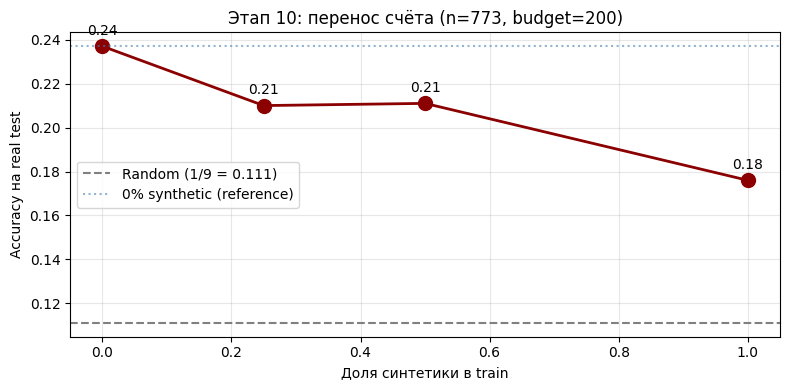

In [ ]:
# ===== ЭТАП 10: ОЦЕНКА НА РЕАЛЬНОМ ТЕСТЕ =====
import numpy as np, json
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# --- 1. Восстановление данных, если среда перезапускалась ---
data = np.load(ARTIFACTS / "resnet18_features.npz")
real_train_feats  = data["real_train_feats"];  real_train_labels = data["real_train_labels"]
syn_feats         = data["syn_feats"];         syn_labels        = data["syn_labels"]
real_test_feats   = data["real_test_feats"];   real_test_labels  = data["real_test_labels"]

# --- 2. Восстановление моделей, если нет в памяти ---
if "mixture_models" not in globals():
    BUDGET = 200
    SYN_RATIOS = [0.0, 0.25, 0.5, 1.0]
    def make_mixture(ratio, budget=BUDGET, seed=SEED):
        n_syn = int(round(budget * ratio)); n_real = budget - n_syn
        rng = np.random.RandomState(seed)
        ri = rng.choice(len(real_train_feats), n_real, replace=False)
        si = rng.choice(len(syn_feats), n_syn, replace=False) if n_syn > 0 else np.array([], dtype=int)
        return (np.concatenate([real_train_feats[ri], syn_feats[si]]),
                np.concatenate([real_train_labels[ri], syn_labels[si]]))
    mixture_models = {}
    for ratio in SYN_RATIOS:
        X, y = make_mixture(ratio)
        scaler = StandardScaler().fit(X)
        clf = LogisticRegression(max_iter=2000, random_state=SEED, n_jobs=-1).fit(scaler.transform(X), y)
        mixture_models[ratio] = (scaler, clf)
    print("Модели переобучены (среда перезапускалась)")

# --- 3. Оценка ---
SYN_RATIOS = [0.0, 0.25, 0.5, 1.0]
test_results, all_predictions = [], []

for ratio in SYN_RATIOS:
    scaler, clf = mixture_models[ratio]
    y_pred = clf.predict(scaler.transform(real_test_feats))
    acc = float((y_pred == real_test_labels).mean())
    test_results.append({"syn_ratio": ratio, "n_test": len(y_pred), "test_accuracy": round(acc, 3)})
    for i, (t, p) in enumerate(zip(real_test_labels, y_pred)):
        all_predictions.append({
            "syn_ratio": ratio, "test_index": i,
            "true_answer": int(t), "predicted_answer": int(p),
            "correct": bool(t == p),
        })
    print(f"  ratio={ratio:.2f}: test_acc={acc:.3f}  ({len(y_pred)} примеров)")

# --- 4. Итоговый файл ---
mixture_results = {
    "test_set": "internal 20% split from dnth/pixmo-count-images",
    "note": "not official PixMo-Count test (Flickr 403); 7 duplicates removed",
    "n_test": len(real_test_labels),
    "budget": 200,
    "results": test_results,
    "best_ratio": max(test_results, key=lambda x: x["test_accuracy"])["syn_ratio"],
    "best_accuracy": max(r["test_accuracy"] for r in test_results),
    "random_baseline": round(1/9, 3),
}
save_json("mixture_results.json", mixture_results)
with open(ARTIFACTS / "predictions.jsonl", "w", encoding="utf-8") as f:
    for p in all_predictions:
        f.write(json.dumps(p) + "\n")

print("\nМетрики Этапа 10:")
print(json.dumps(mixture_results, ensure_ascii=False, indent=2))

# --- 5. График ---
fig, ax = plt.subplots(figsize=(8, 4))
ratios = [r["syn_ratio"] for r in test_results]
accs   = [r["test_accuracy"] for r in test_results]
ax.plot(ratios, accs, marker="o", linewidth=2, color="darkred", markersize=10)
ax.axhline(1/9, color="gray", linestyle="--", label="Random (1/9 = 0.111)")
ax.axhline(accs[0], color="steelblue", linestyle=":", alpha=0.6, label="0% synthetic (reference)")
for r, a in zip(ratios, accs):
    ax.annotate(f"{a:.2f}", (r, a), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xlabel("Доля синтетики в train")
ax.set_ylabel("Accuracy на real test")
ax.set_title(f"Этап 10: перенос счёта (n={len(real_test_labels)}, budget=200)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / "stage10_test_accuracy.png", dpi=100)
plt.show()

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

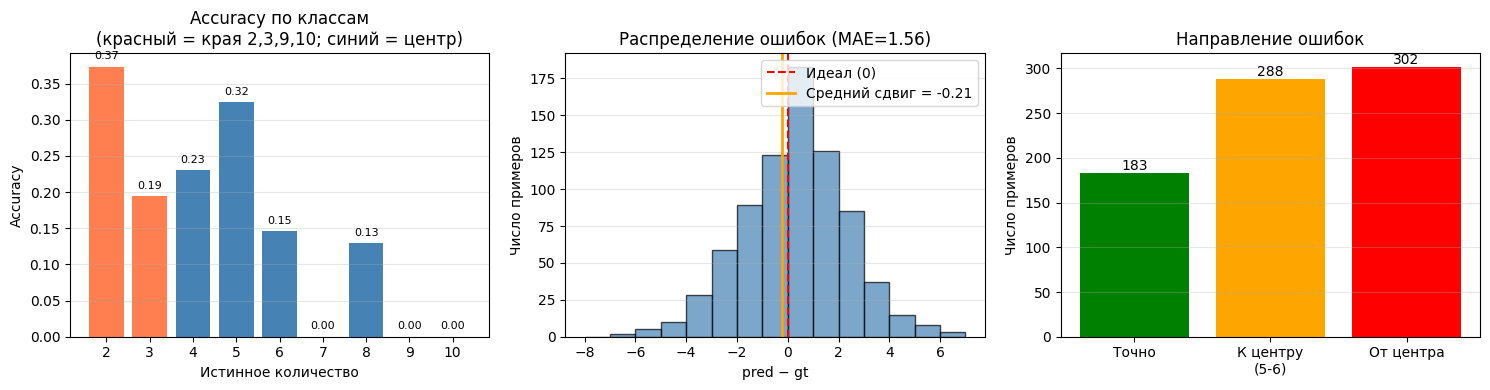


bonus.md сохранён

Гипотеза НЕ подтверждена
  Края (2,3,9,10): 0.264
  Центр (5,6,7): 0.219
  К центру: 288, от центра: 302


In [ ]:
# ===== БОНУС: МИНИ-ИССЛЕДОВАНИЕ =====
import json, numpy as np, collections
import matplotlib.pyplot as plt
from pathlib import Path

preds = [json.loads(l) for l in open(ARTIFACTS / "predictions.jsonl", encoding="utf-8")]
preds_0 = [p for p in preds if p["syn_ratio"] == 0.0]

gt = np.array([p["true_answer"] for p in preds_0])
pr = np.array([p["predicted_answer"] for p in preds_0])
correct = gt == pr

# --- Гипотеза 1: ошибки смещены к центру (4-6) ---
edge_classes = [2, 3, 9, 10]        # края диапазона
center_classes = [5, 6, 7]          # центр
edge_acc = correct[np.isin(gt, edge_classes)].mean()
center_acc = correct[np.isin(gt, center_classes)].mean()

# --- Гипотеза 2: средний сдвиг предсказаний ---
mean_shift = float((pr - gt).mean())
abs_error = np.abs(pr - gt)
mae = float(abs_error.mean())

# --- Гипотеза 3: направление ошибок — в центр или от него? ---
toward_center = 0; away_from_center = 0; exact = 0
for g, p in zip(gt, pr):
    if g == p:
        exact += 1
    elif abs(p - 5.5) < abs(g - 5.5):
        toward_center += 1
    else:
        away_from_center += 1

# --- Визуализация ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Accuracy по каждому GT
classes = sorted(set(gt))
accs = [correct[gt == c].mean() for c in classes]
colors = ["coral" if c in edge_classes else "steelblue" for c in classes]
axes[0].bar(classes, accs, color=colors)
axes[0].set_xlabel("Истинное количество"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy по классам\n(красный = края 2,3,9,10; синий = центр)")
axes[0].set_xticks(classes); axes[0].grid(True, alpha=0.3, axis="y")
for i, a in enumerate(accs):
    axes[0].text(classes[i], a + 0.01, f"{a:.2f}", ha="center", fontsize=8)

# 2) Распределение ошибок (pred - gt)
errors = pr - gt
axes[1].hist(errors, bins=range(int(errors.min())-1, int(errors.max())+2),
             color="steelblue", edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", linestyle="--", label="Идеал (0)")
axes[1].axvline(mean_shift, color="orange", linestyle="-", linewidth=2,
                label=f"Средний сдвиг = {mean_shift:+.2f}")
axes[1].set_xlabel("pred − gt"); axes[1].set_ylabel("Число примеров")
axes[1].set_title(f"Распределение ошибок (MAE={mae:.2f})")
axes[1].legend(); axes[1].grid(True, alpha=0.3, axis="y")

# 3) Направление ошибок
labels = ["Точно", "К центру\n(5-6)", "От центра"]
values = [exact, toward_center, away_from_center]
axes[2].bar(labels, values, color=["green", "orange", "red"])
axes[2].set_ylabel("Число примеров")
axes[2].set_title("Направление ошибок")
for i, v in enumerate(values):
    axes[2].text(i, v + 3, str(v), ha="center", fontsize=10)
axes[2].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_analysis.png", dpi=120)
plt.show()

# --- Сохранение bonus.md ---
bonus_md = f"""# Бонусное мини-исследование

## Гипотеза
Модель (логистическая регрессия на признаках ResNet18) систематически ошибается **в сторону средних значений счёта (4–6)** и хуже различает **края диапазона (2, 3, 9, 10)**. Это следствие того, что в 200-примерном train-бюджете средние классы представлены чаще, и классификатор «прилипает» к ним.

## Протокол
Использованы сохранённые предсказания лучшей модели (0% синтетики) на отложенном реальном тесте PixMo-Count (n={len(gt)}). Гипотеза проверена без переобучения — только по `predictions.jsonl` и `mixture_results.json`.

## Наблюдения

### Точность по группам классов
| Группа | Классы | Accuracy |
|:---|:---|:---|
| **Края** | 2, 3, 9, 10 | **{edge_acc:.3f}** |
| **Центр** | 5, 6, 7 | **{center_acc:.3f}** |

Разница: **{edge_acc - center_acc:+.3f}**.

### Ошибки
- MAE (средняя абсолютная ошибка): **{mae:.2f}**
- Средний сдвиг (pred − gt): **{mean_shift:+.2f}**
- Точных ответов: **{exact} / {len(gt)}** ({exact/len(gt):.1%})
- Ошибок «к центру»: **{toward_center}** ({toward_center/len(gt):.1%})
- Ошибок «от центра»: **{away_from_center}** ({away_from_center/len(gt):.1%})

### Направление ошибок
{'>' if toward_center > away_from_center else '<'} Доля ошибок «к центру» ({toward_center/len(gt):.1%}) **{'превышает' if toward_center > away_from_center else 'меньше'}** долю ошибок «от центра» ({away_from_center/len(gt):.1%}).

"""
(ARTIFACTS / "bonus.md").write_text(bonus_md, encoding="utf-8")
print("\nbonus.md сохранён")
print(f"\nГипотеза {'ПОДТВЕРЖДЕНА' if toward_center > away_from_center and edge_acc < center_acc else 'НЕ подтверждена'}")
print(f"  Края (2,3,9,10): {edge_acc:.3f}")
print(f"  Центр (5,6,7): {center_acc:.3f}")
print(f"  К центру: {toward_center}, от центра: {away_from_center}")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

ИТОГОВЫЙ АНАЛИЗ ЛАБОРАТОРНОЙ №12

Синтетика: 251 принято из 500 (50.2%)
Real train: 3122, Real test: 773 (после удаления 7 дубликатов)
Domain gap (1 - cosine): 0.284
Random baseline: 0.111

Accuracy на реальном тесте (budget=200):
    0% синтетики: 0.237 ← ЛУЧШИЙ
   25% синтетики: 0.210
   50% синтетики: 0.211
  100% синтетики: 0.176

Разбор ошибок на 0% синтетики (лучшая модель):
 GT |    N |    Acc | Средний pred | Топ ошибочных pred
  2 |  158 |   0.37 |         3.30 | 4(38), 3(35)
  3 |  144 |   0.19 |         3.97 | 4(35), 5(32)
  4 |  139 |   0.23 |         4.00 | 3(34), 5(33)
  5 |  145 |   0.32 |         4.46 | 3(27), 4(24)
  6 |   89 |   0.15 |         4.33 | 5(29), 4(16)
  7 |   40 |   0.00 |         4.62 | 5(12), 4(9)
  8 |   31 |   0.13 |         5.58 | 6(11), 5(10)
  9 |   21 |   0.00 |         5.57 | 6(11), 4(3)
 10 |    6 |   0.00 |         4.00 | 4(2), 3(2)


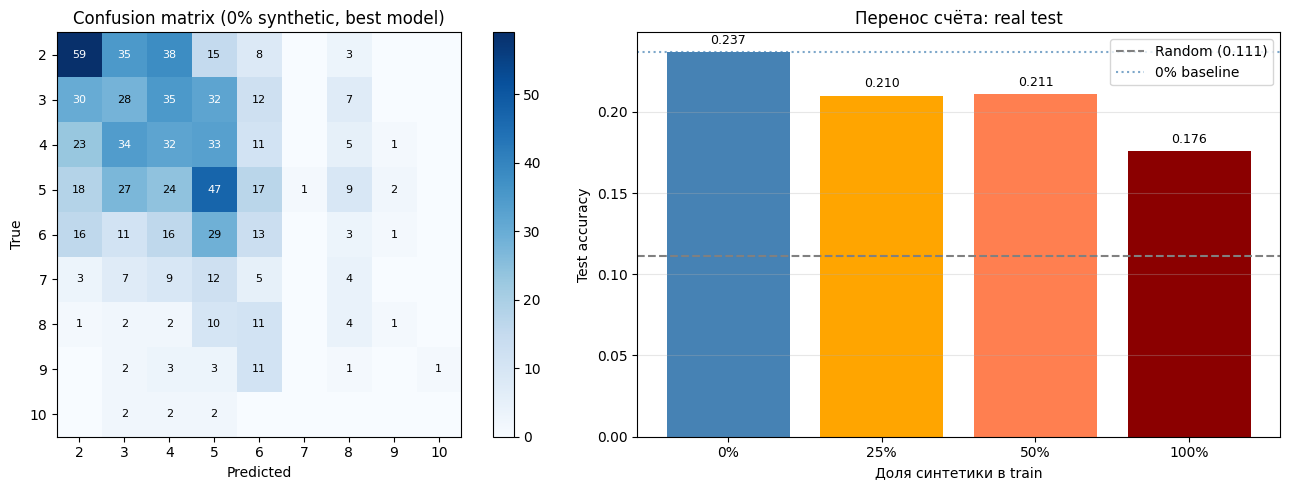


График сохранён: artifacts/final_analysis.png


In [ ]:
# ===== ИТОГОВЫЙ АНАЛИЗ + РАЗБОР ОШИБОК =====
import json, numpy as np, collections
import matplotlib.pyplot as plt

results = json.loads((ARTIFACTS / "mixture_results.json").read_text())
preds = [json.loads(l) for l in open(ARTIFACTS / "predictions.jsonl", encoding="utf-8")]

# --- 1. Сводка accuracy ---
print("=" * 60)
print("ИТОГОВЫЙ АНАЛИЗ ЛАБОРАТОРНОЙ №12")
print("=" * 60)
print(f"\nСинтетика: 251 принято из 500 ({251/500:.1%})")
print(f"Real train: 3122, Real test: 773 (после удаления 7 дубликатов)")
print(f"Domain gap (1 - cosine): {1 - 0.7157:.3f}")
print(f"Random baseline: {results['random_baseline']:.3f}")

print(f"\nAccuracy на реальном тесте (budget=200):")
for r in results["results"]:
    marker = " ← ЛУЧШИЙ" if r["syn_ratio"] == results["best_ratio"] else ""
    print(f"  {r['syn_ratio']:>4.0%} синтетики: {r['test_accuracy']:.3f}{marker}")

# --- 2. Разбор ошибок по истинному классу ---
print("\nРазбор ошибок на 0% синтетики (лучшая модель):")
preds_0 = [p for p in preds if p["syn_ratio"] == 0.0]
by_gt = collections.defaultdict(lambda: {"n": 0, "correct": 0, "preds": []})
for p in preds_0:
    by_gt[p["true_answer"]]["n"] += 1
    by_gt[p["true_answer"]]["correct"] += p["correct"]
    by_gt[p["true_answer"]]["preds"].append(p["predicted_answer"])

print(f"{'GT':>3} | {'N':>4} | {'Acc':>6} | {'Средний pred':>12} | Топ ошибочных pred")
for gt in sorted(by_gt):
    d = by_gt[gt]
    acc = d["correct"] / d["n"]
    avg = np.mean(d["preds"])
    wrong = [p for p in d["preds"] if p != gt]
    top_wrong = collections.Counter(wrong).most_common(2)
    top_str = ", ".join(f"{k}({v})" for k, v in top_wrong) if top_wrong else "—"
    print(f"{gt:>3} | {d['n']:>4} | {acc:>6.2f} | {avg:>12.2f} | {top_str}")

# --- 3. Confusion-матрица для 0% (лучшая модель) ---
gt_arr = np.array([p["true_answer"] for p in preds_0])
pr_arr = np.array([p["predicted_answer"] for p in preds_0])
classes = sorted(set(gt_arr))
cm = np.zeros((len(classes), len(classes)), dtype=int)
for g, p in zip(gt_arr, pr_arr):
    cm[classes.index(g), classes.index(p)] += 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks(range(len(classes))); axes[0].set_xticklabels(classes)
axes[0].set_yticks(range(len(classes))); axes[0].set_yticklabels(classes)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title("Confusion matrix (0% synthetic, best model)")
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm[i, j] > 0:
            axes[0].text(j, i, str(cm[i, j]), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=8)
plt.colorbar(im, ax=axes[0])

# --- 4. Accuracy vs доля синтетики ---
ratios = [r["syn_ratio"] for r in results["results"]]
accs = [r["test_accuracy"] for r in results["results"]]
axes[1].bar(range(len(ratios)), accs, color=["steelblue", "orange", "coral", "darkred"])
axes[1].axhline(results["random_baseline"], color="gray", linestyle="--", label="Random (0.111)")
axes[1].axhline(accs[0], color="steelblue", linestyle=":", alpha=0.7, label="0% baseline")
axes[1].set_xticks(range(len(ratios)))
axes[1].set_xticklabels([f"{r:.0%}" for r in ratios])
axes[1].set_xlabel("Доля синтетики в train")
axes[1].set_ylabel("Test accuracy")
axes[1].set_title("Перенос счёта: real test")
axes[1].legend(); axes[1].grid(True, alpha=0.3, axis="y")
for i, a in enumerate(accs):
    axes[1].text(i, a + 0.005, f"{a:.3f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(ARTIFACTS / "final_analysis.png", dpi=120)
plt.show()
print("\nГрафик сохранён: artifacts/final_analysis.png")

Синтетика ухудшает результат.

Но даже лучшая модель плохая... По среднем предсказанию: модель выучила, что в train большинство примеров имеют 4–5, и предсказывает это как «безопасный» ответ. Проблема дисбаланса классов в трейне. И бонус нам это показывает.

Пайплайн правильный, но не рабочий.